In [17]:
import numpy as np 
import pandas as pd 
from __future__ import annotations
import matplotlib.pyplot as plt

In [2]:
def _time_grid(T: float, steps: int) -> tuple[float, np.ndarray]:
    """ Returns dt and time axis. """
    dt = T / steps
    return dt, np.linspace(0.0, T, steps+1)

In [3]:
def _init_paths(r0: float, steps: int, n_sims: int) -> np.ndarray:
    """Create simulations matrix and set initial value."""
    paths = np.zeros((steps + 1, n_sims)) # Corrected function name and variable
    paths[0] = r0
    return paths

In [4]:
def simulate_vasicek(
    r0: float,
    a: float,
    b: float,
    sigma: float,
    T: float = 1.0,
    steps: int = 100,
    n_sims: int = 1000,
) -> np.ndarray:
    """ 
    Vasicek Model
    dr = a (b - rt) dt + sigma dw 
    """
    dt, _ = _time_grid(T, steps)
    rates = _init_paths(r0, steps, n_sims)

    for t in range(1, steps+1):
        noise = np.random.normal(0.0, np.sqrt(dt), n_sims)
        dr = a * (b - rates [t-1]) * dt + sigma * noise
        rates[t] = rates [t-1] + dr

    return rates

In [9]:
def simulate_log_diffusion(
    r0: float,
    sigma: float,
    T: float = 1.0,
    steps: int = 100,
    n_sims: int = 1000,
) -> np.ndarray:
    """
    Pure Lognormal Diffusion
    d(ln r) = sigma dw
    """
    dt, _ = _time_grid(T, steps)
    rates = _init_paths(r0,steps,n_sims)

    log_r = np.full(n_sims, np.log(r0))

    for t in range(1, steps+1):
        noise = np.random.normal(0.0, np.sqrt(dt), n_sims)
        log_r += sigma * noise - 0.5 * sigma ** 2 * dt
        rates[t] = np.exp(log_r)
        
    return rates

In [23]:
def simulate_log_mean_reverting(
    r0: float,
    a: float,
    b: float,
    sigma: float,
    T: float = 1.0,
    steps: int = 100,
    n_sims: int = 1000,
) -> np.ndarray:
    """
    Exponential Vasicek
    d(ln r) = a(ln b - ln r)dt + sigma_dw
    """
    dt, _ = _time_grid(T, steps)
    rates = _init_paths(r0, steps, n_sims)

    log_r = np.full(n_sims, np.log(r0))
    log_b = np.log(b)

    for t in range(1, steps+1):
        noise = np.random.normal(0.0, np.sqrt(dt), n_sims)
        log_r += a * (log_b - log_r) * dt + sigma * noise
        rates[t] = np.exp(log_r)
        
    return rates

In [13]:
def simulate_cir(
    r0: float,
    a: float,
    b: float,
    sigma: float,
    T: float = 1.0,
    steps: int = 100,
    n_sims: int = 1000,
) -> np.ndarray:
    """
    Cox - Ingersoll - Rosss Model
    dr = a(b - rt)dt + sigma sqrt(r) dw
    Ensures non-negative rates
    """
    dt, _ = _time_grid(T, steps)
    rates =  _init_paths(r0, steps, n_sims)

    for t in range(1, steps+1):
        noise = np.random.normal(0.0, np.sqrt(dt), n_sims)
        prev = np.maximum(rates[t-1], 0.0)
        dr = a * (b - prev) * dt + sigma * np.sqrt(prev) * noise
        rates[t] = rates[t-1] + dr

    return rates

In [32]:
def simulate_gbm(
    r0: float,
    mu: float,
    sigma: float,
    T: float = 1.0,
    steps: int = 100,
    n_sims: int = 1000,
)  -> np.ndarray:
    """
    Geometric Brownian Motion
    dr = mu r dt + sigma r dw
    """
    dt, _ = _time_grid(T, steps)
    rates = _init_paths(r0, steps, n_sims)

    for t in range(1, steps+1):
        noise = np.random.normal(0.0, np.sqrt(dt), n_sims)
        rates[t] = rates[t - 1] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * noise)

    return rates

In [33]:
def plot_paths(data: np.ndarray, title: str, T: float, color: str = "blue") -> None:
    """ Plot same paths and mean trajectory. """
    steps = data.shape[0] - 1
    _, time_axis = _time_grid (T, steps)

    plt.figure(figsize=(10,15))
    plt.plot(time_axis, data[:, :50], color=color, alpha=0.1)
    plt.plot(time_axis, np.mean(data, axis=1), color="black", linewidth=2, label="Mean")

    plt.title(title)
    plt.xlabel("Years")
    plt.ylabel("Rate")
    plt.grid(alpha = 0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

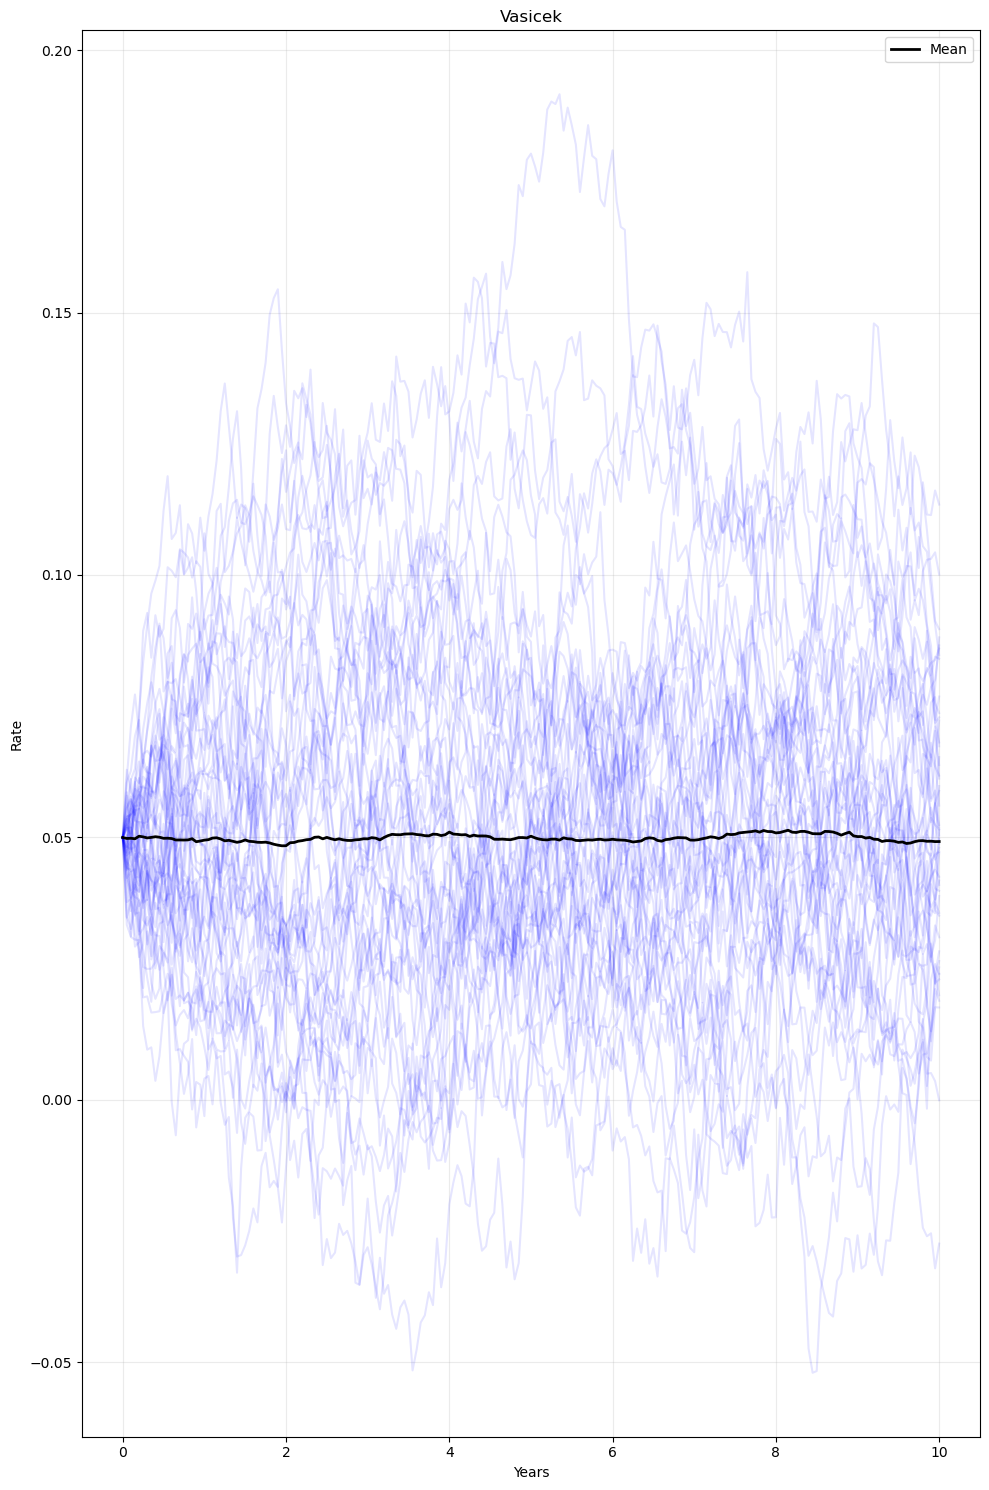

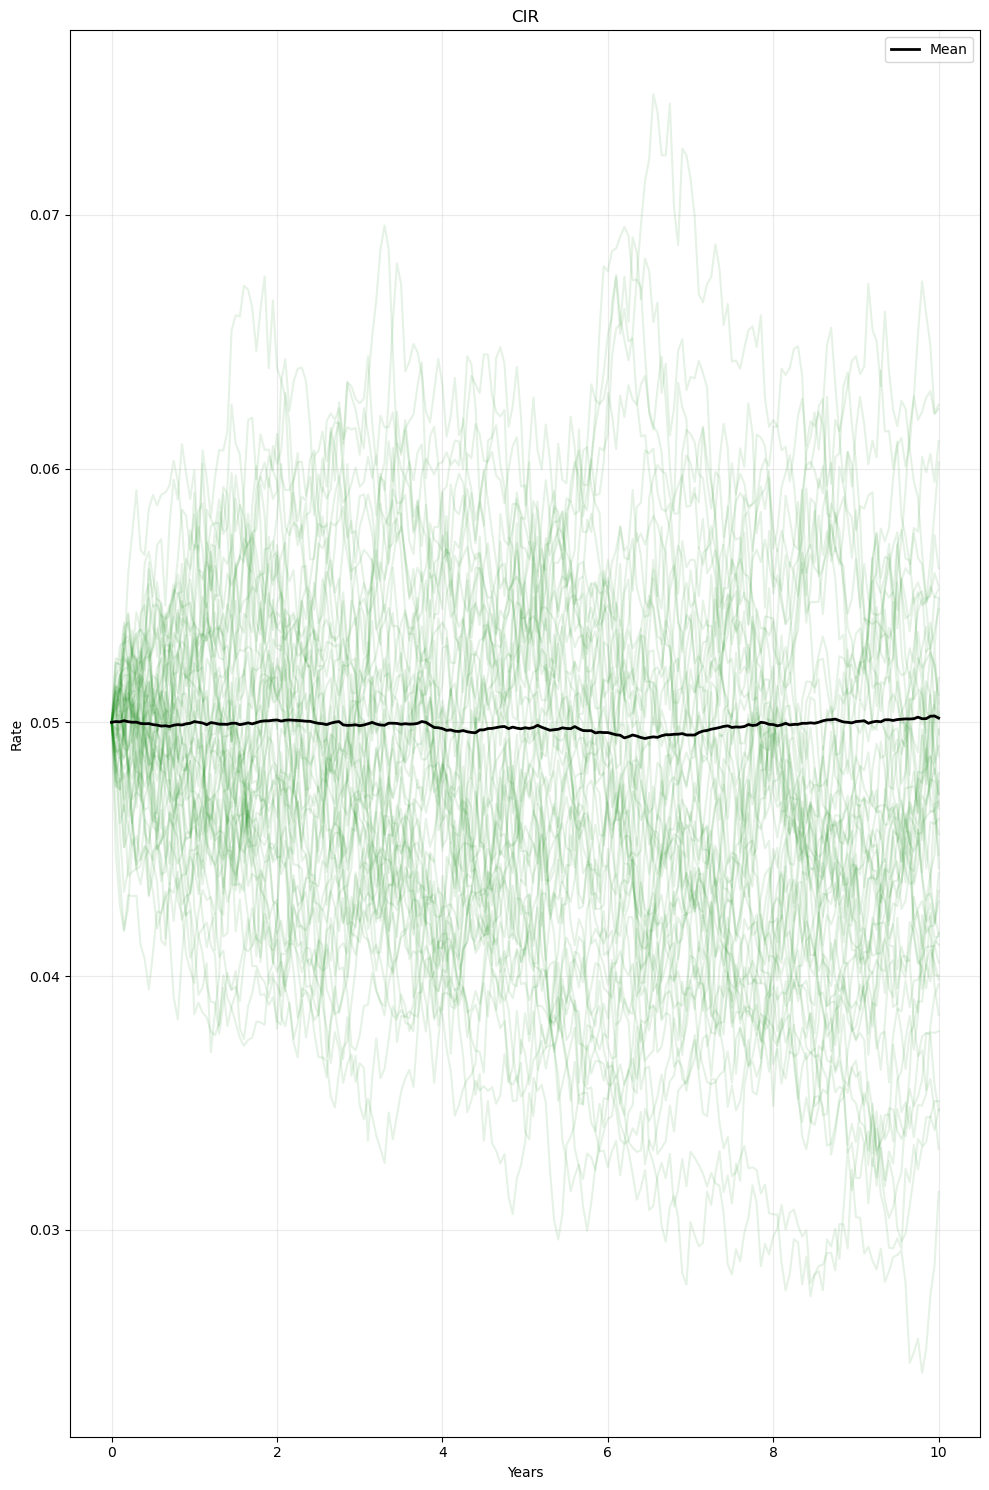

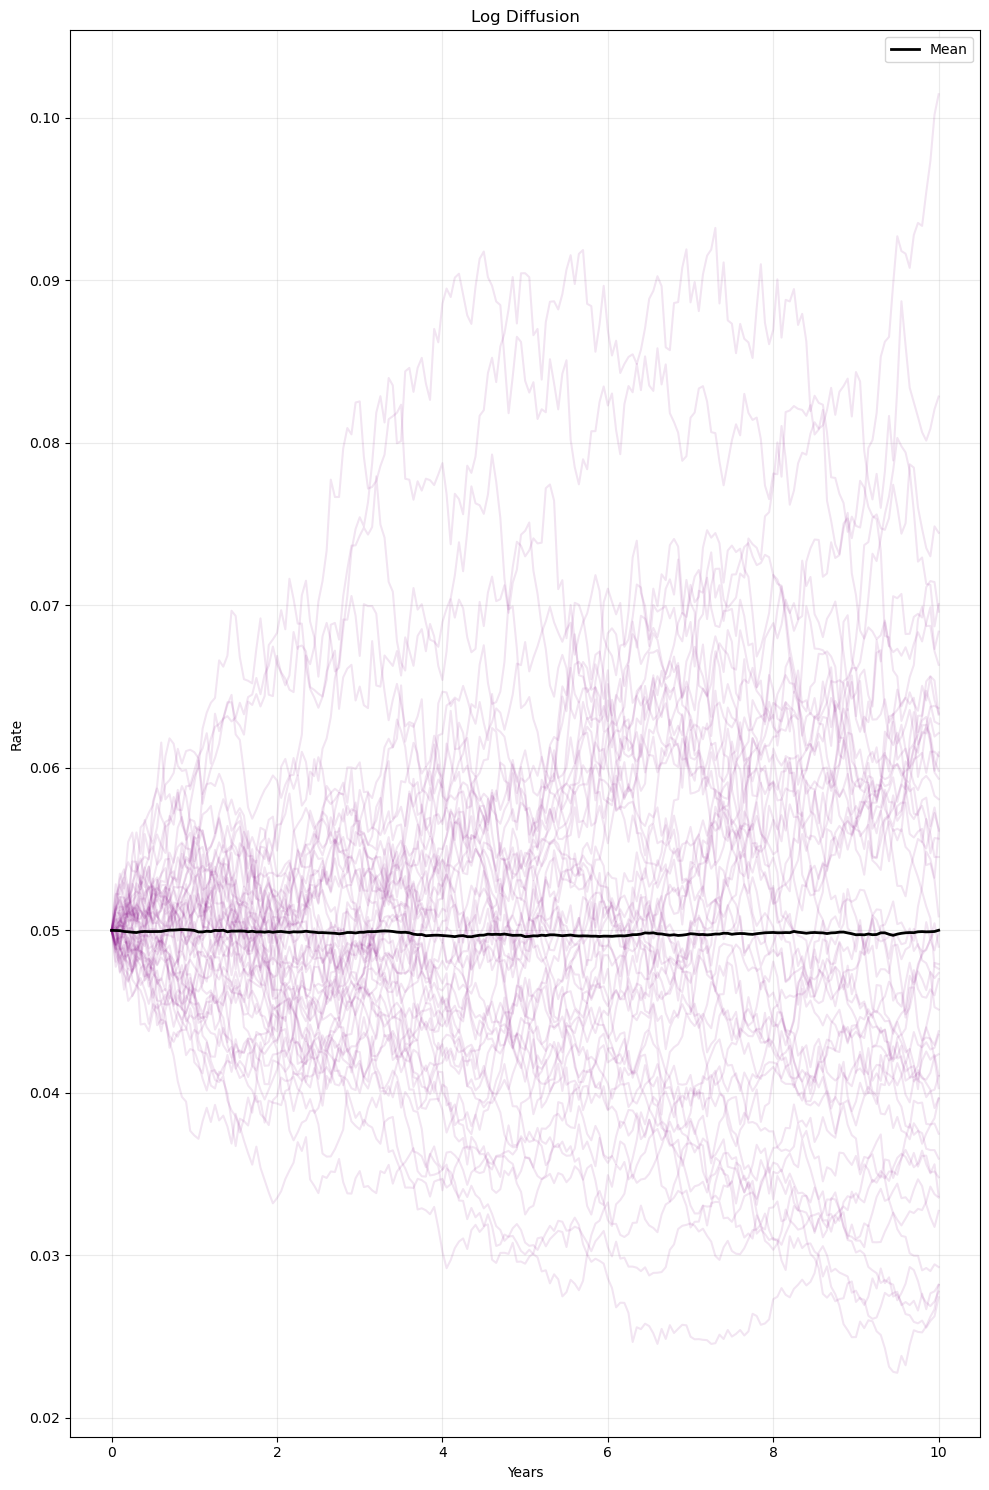

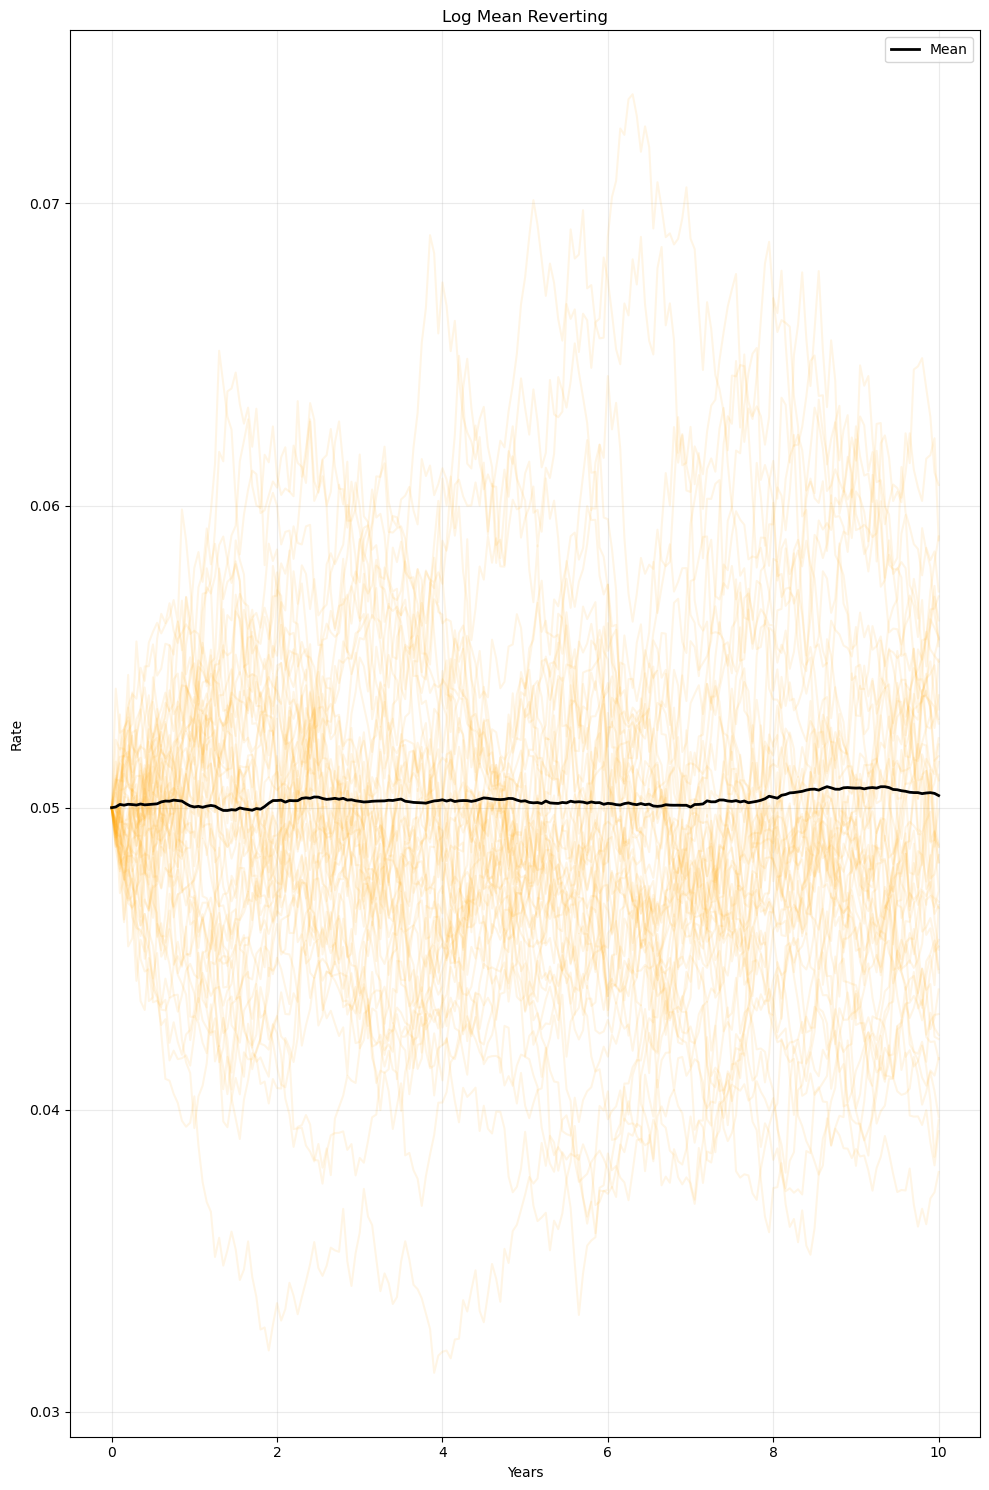

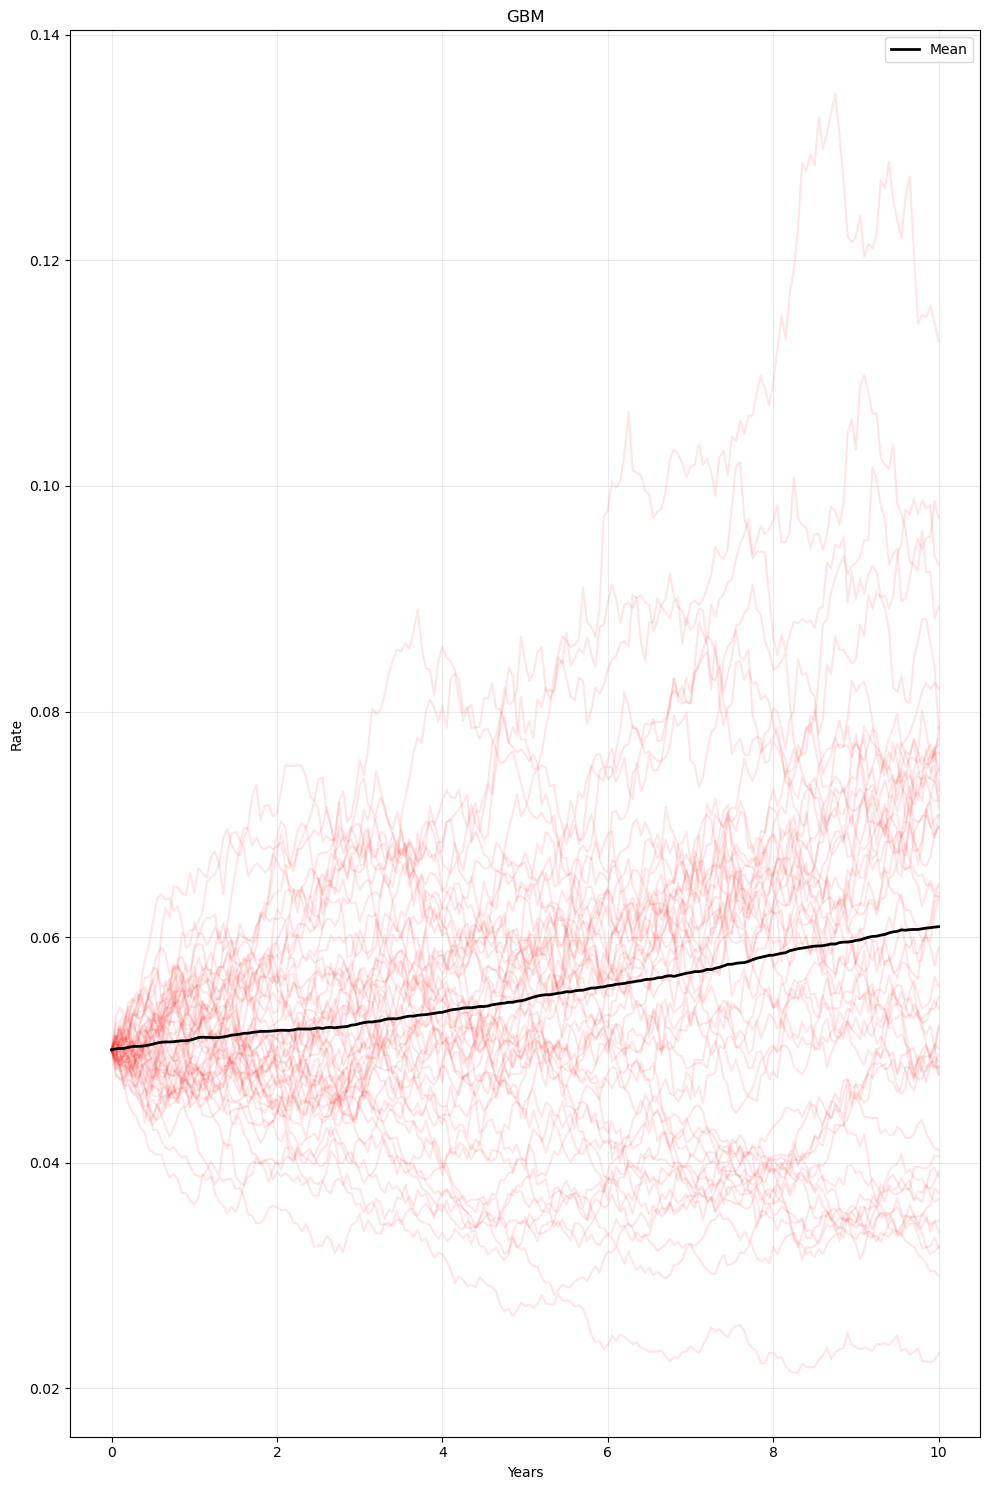

In [34]:
 if __name__ == "__main__":
    r0 = 0.05
    a = 0.3
    b = 0.05
    sigma = 0.03
    T = 10
    steps = 200
    n_sims = 1000

    plot_paths(simulate_vasicek(r0, a, b, sigma, T, steps, n_sims), "Vasicek", T)
    plot_paths(simulate_cir(r0, a, b, sigma, T, steps, n_sims), "CIR", T, "green")
    plot_paths(simulate_log_diffusion(r0, 0.1, T, steps, n_sims), "Log Diffusion", T, "purple")
    plot_paths(simulate_log_mean_reverting(r0, a, b, 0.1, T, steps, n_sims), "Log Mean Reverting", T, "orange")
    plot_paths(simulate_gbm(r0, 0.02, 0.1, T, steps, n_sims), "GBM", T, "red")
